# How unnecessary conditioning creates bias

Suppose the outcome causes part of a variable that is also caused by the exposure:

$$
Y=\beta X+U,
\qquad
Z=\gamma Y+\delta X+V,
\qquad
\widehat\beta=\frac{\beta-\delta\gamma}{1+\gamma^2},
\qquad
\widehat\theta=\frac{\gamma}{1+\gamma^2}.
$$

Here, $X$ is the exposure, $Y$ is the outcome, $Z$ is their common outcome and therefore a collider, $U$ and $V$ are independent centered unit-variance disturbances, $\beta$ is the causal effect of $X$ on $Y$, $\gamma$ links $Y$ to $Z$, $\delta$ links $X$ to $Z$, and $\widehat\beta$ and $\widehat\theta$ are the population coefficients on $X$ and $Z$ after conditioning on the collider.

,Direct effect,Outcome-to-collider link,Exposure-to-collider link,Conditioned exposure coefficient,Conditioned collider coefficient,Exposure-coefficient error
0,0.5,1,0.8,-0.15,0.5,-0.65
1,1,-2,0.25,0.3,-0.4,-0.7
2,-0.7,0.4,-1.2,-0.189655,0.344828,0.510345
3,0.7,1.5,-1.05,0.7,0.461538,0
4,0.7,0,4,0.7,0,0


,Specification,Exposure coefficient,Exposure target,Collider coefficient,Collider target,Explained variance,Observations,Seed
0,Collider omitted,0.501504,0.5,NaN,NaN,0.199529,5000,0
1,Collider included,-0.145944,-0.15,0.498828,0.5,0.599114,5000,0


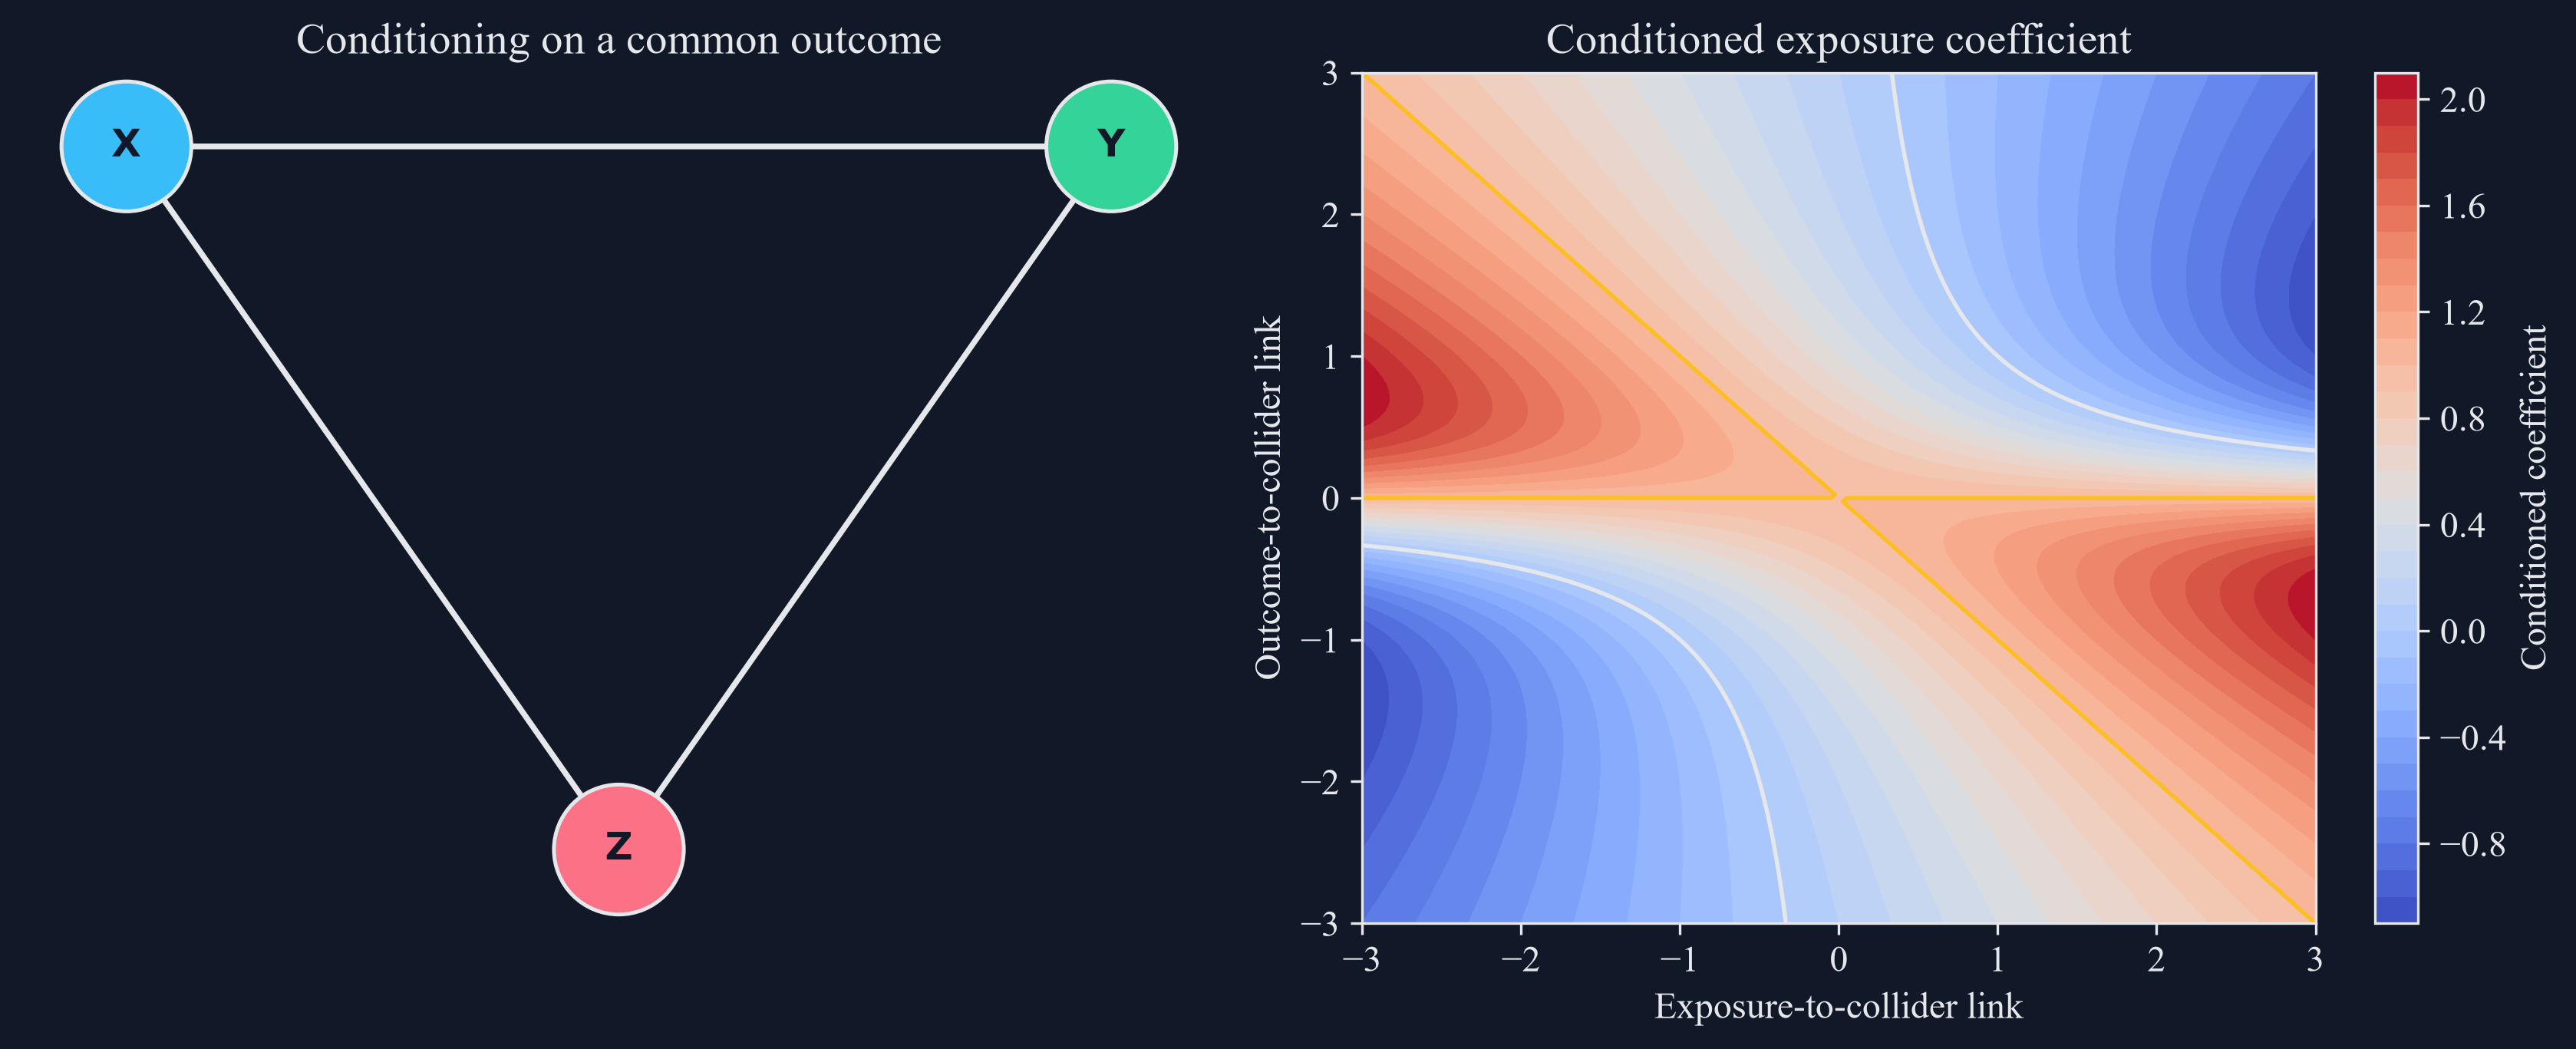

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
from dataclasses import FrozenInstanceError
import inspect
import math
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]

from RiskLabAI.causal_factor_analysis import ColliderCoefficients, ColliderDiagnostics, PopulationRegressionDiagnostics, RegressionDiagnostics, SpecificationExperimentResult, SpecificationPopulationResult, StrategyPerformance, collider_factor_return, collider_forecast_return, collider_model_diagnostics, collider_overcontrolled_coefficients, collider_population_diagnostics, collider_specification_experiment, confounded_mediator_population_diagnostics, confounded_mediator_specification_experiment, confounder_factor_return, confounder_forecast_return, confounder_undercontrolled_coefficient, fork_population_diagnostics, fork_specification_experiment, generalized_collider_overcontrolled_coefficients, generalized_confounder_undercontrolled_coefficient

FIGURES = ROOT / "outputs" / "figures" / "04_factor_mirage"
TABLES = ROOT / "outputs" / "tables" / "04_factor_mirage"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#111827", "axes": "#111827", "text": "#E5E7EB", "cyan": "#38BDF8", "amber": "#FBBF24", "green": "#34D399", "rose": "#FB7185", "violet": "#C084FC", "grid": "#374151", "muted": "#94A3B8"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def contract_result(name, action, expected):
    try:
        action()
        return {"Check": name, "Expected result": expected, "Observed result": "Accepted", "Passed": False}
    except Exception as error:
        return {"Check": name, "Expected result": expected, "Observed result": type(error).__name__, "Passed": type(error).__name__ == expected}

def draw_graph(axis, nodes, edges, positions, title, colors=None):
    graph = nx.DiGraph()
    graph.add_nodes_from(nodes)
    graph.add_edges_from(edges)
    node_colors = colors if colors is not None else [palette["cyan"]] * len(nodes)
    nx.draw_networkx_nodes(graph, positions, ax=axis, node_color=node_colors, node_size=1650, edgecolors=palette["text"], linewidths=1.2)
    nx.draw_networkx_labels(graph, positions, ax=axis, font_color=palette["background"], font_weight="bold")
    nx.draw_networkx_edges(graph, positions, ax=axis, edge_color=palette["text"], width=1.8, arrows=True, arrowsize=20)
    axis.set_title(title)
    axis.set_axis_off()

def ols_diagnostics(outcome, predictors):
    design = np.column_stack([np.ones(len(outcome))] + [np.asarray(values, dtype=float) for values in predictors.values()])
    coefficients = np.linalg.lstsq(design, np.asarray(outcome, dtype=float), rcond=None)[0]
    residuals = np.asarray(outcome, dtype=float) - design @ coefficients
    residual_degrees = len(outcome) - design.shape[1]
    residual_variance = float(residuals @ residuals / residual_degrees)
    covariance = np.linalg.inv(design.T @ design) * residual_variance
    standard_errors = np.sqrt(np.diag(covariance))
    centered = np.asarray(outcome, dtype=float) - np.mean(outcome)
    r_squared = 1.0 - float(residuals @ residuals) / float(centered @ centered)
    adjusted = 1.0 - (1.0 - r_squared) * (len(outcome) - 1) / residual_degrees
    names = ["Intercept"] + list(predictors)
    return pd.DataFrame({"Coefficient": names, "Estimate": coefficients, "Standard error": standard_errors, "Test signal": coefficients / standard_errors}), r_squared, adjusted, residual_variance

def coefficient_value(diagnostics, name):
    return diagnostics.coefficients[diagnostics.coefficient_names.index(name)]

standardized_cases = [(0.5, 1.0, 0.8), (1.0, -2.0, 0.25), (-0.7, 0.4, -1.2), (0.7, 1.5, -1.05), (0.7, 0.0, 4.0)]
standardized_rows = []
for beta, gamma, delta in standardized_cases:
    result = collider_overcontrolled_coefficients(beta, gamma, delta)
    standardized_rows.append({"Direct effect": beta, "Outcome-to-collider link": gamma, "Exposure-to-collider link": delta, "Conditioned exposure coefficient": result.beta_hat, "Conditioned collider coefficient": result.theta_hat, "Exposure-coefficient error": result.beta_hat - beta})
standardized_table = pd.DataFrame(standardized_rows)
save_table(standardized_table, "collider_standardized_coefficients", "Population coefficients after conditioning on the collider.", "tab:chapter26-collider-standardized")
display(standardized_table)

beta = 0.5
gamma = 1.0
delta = 0.8
sample_size = 5000
random_state = np.random.RandomState(0)
exposure = random_state.standard_normal(sample_size)
outcome_noise = random_state.standard_normal(sample_size)
collider_noise = random_state.standard_normal(sample_size)
outcome = beta * exposure + outcome_noise
collider = gamma * outcome + delta * exposure + collider_noise
unconditioned_diagnostics, unconditioned_r2, _, _ = ols_diagnostics(outcome, {"Exposure": exposure})
conditioned_diagnostics, conditioned_r2, _, _ = ols_diagnostics(outcome, {"Exposure": exposure, "Collider": collider})
population = collider_overcontrolled_coefficients(beta, gamma, delta)
generated_table = pd.DataFrame([
    {"Specification": "Collider omitted", "Exposure coefficient": unconditioned_diagnostics.loc[1, "Estimate"], "Exposure target": beta, "Collider coefficient": np.nan, "Collider target": np.nan, "Explained variance": unconditioned_r2, "Observations": sample_size, "Seed": 0},
    {"Specification": "Collider included", "Exposure coefficient": conditioned_diagnostics.loc[1, "Estimate"], "Exposure target": population.beta_hat, "Collider coefficient": conditioned_diagnostics.loc[2, "Estimate"], "Collider target": population.theta_hat, "Explained variance": conditioned_r2, "Observations": sample_size, "Seed": 0},
])
save_table(generated_table, "collider_generated_check", "A visible fixed-seed collider experiment.", "tab:chapter26-collider-generated")
display(generated_table)

gamma_grid = np.linspace(-3.0, 3.0, 241)
delta_grid = np.linspace(-3.0, 3.0, 241)
gamma_mesh, delta_mesh = np.meshgrid(gamma_grid, delta_grid)
coefficient_mesh = (1.0 - delta_mesh * gamma_mesh) / (1.0 + gamma_mesh ** 2)
figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.7))
draw_graph(axes[0], ("X", "Y", "Z"), (("X", "Y"), ("X", "Z"), ("Y", "Z")), {"X": (0.0, 0.0), "Y": (1.8, 0.0), "Z": (0.9, -1.0)}, "Conditioning on a common outcome", [palette["cyan"], palette["green"], palette["rose"]])
image = axes[1].contourf(delta_mesh, gamma_mesh, coefficient_mesh, levels=31, cmap="coolwarm")
axes[1].contour(delta_mesh, gamma_mesh, coefficient_mesh, levels=[0.0, 1.0], colors=[palette["text"], palette["amber"]], linewidths=1.3)
axes[1].set_xlabel("Exposure-to-collider link")
axes[1].set_ylabel("Outcome-to-collider link")
axes[1].set_title("Conditioned exposure coefficient")
figure.colorbar(image, ax=axes[1], label="Conditioned coefficient")
figure.tight_layout()
save_figure(figure, "collider_graph_and_coefficient")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#111827", "axes.facecolor": "#111827", "axes.edgecolor": "#94A3B8", "axes.labelcolor": "#E5E7EB", "axes.titlecolor": "#E5E7EB", "axes.titleweight": "bold", "xtick.color": "#94A3B8", "ytick.color": "#94A3B8", "text.color": "#E5E7EB", "grid.color": "#374151", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#111827", "legend.edgecolor": "#374151", "legend.framealpha": 0.96, "savefig.facecolor": "#111827", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## General disturbance variances

With general positive disturbance variances, the conditioned coefficients become:

$$
\widehat\beta
=\frac{\beta\sigma_V^2-\delta\gamma\sigma_U^2}
{\sigma_V^2+\gamma^2\sigma_U^2},
\qquad
\widehat\theta
=\frac{\gamma\sigma_U^2}
{\sigma_V^2+\gamma^2\sigma_U^2}.
$$

Here, $\sigma_U^2=\operatorname{Var}(U)$ is the outcome-disturbance variance, $\sigma_V^2=\operatorname{Var}(V)$ is the collider-disturbance variance, and the remaining symbols retain their meanings from the collider system; both variances must be strictly positive.

,Case,Direct effect,Outcome link,Exposure link,Outcome-noise variance,Collider-noise variance,Exposure coefficient,Collider coefficient
0,Unequal variances,0.8,1.2,-0.4,2,3,0.571429,0.408163
1,Small outcome disturbance,-0.5,0.75,2,0.25,4,-0.573585,0.045283
2,Large outcome disturbance,2,-1,-0.25,3.5,0.5,0.03125,-0.875
3,No outcome-to-collider link,1.25,0,7,5,2,1.25,0
4,Unit variances,0.5,1,0.8,1,1,-0.15,0.5


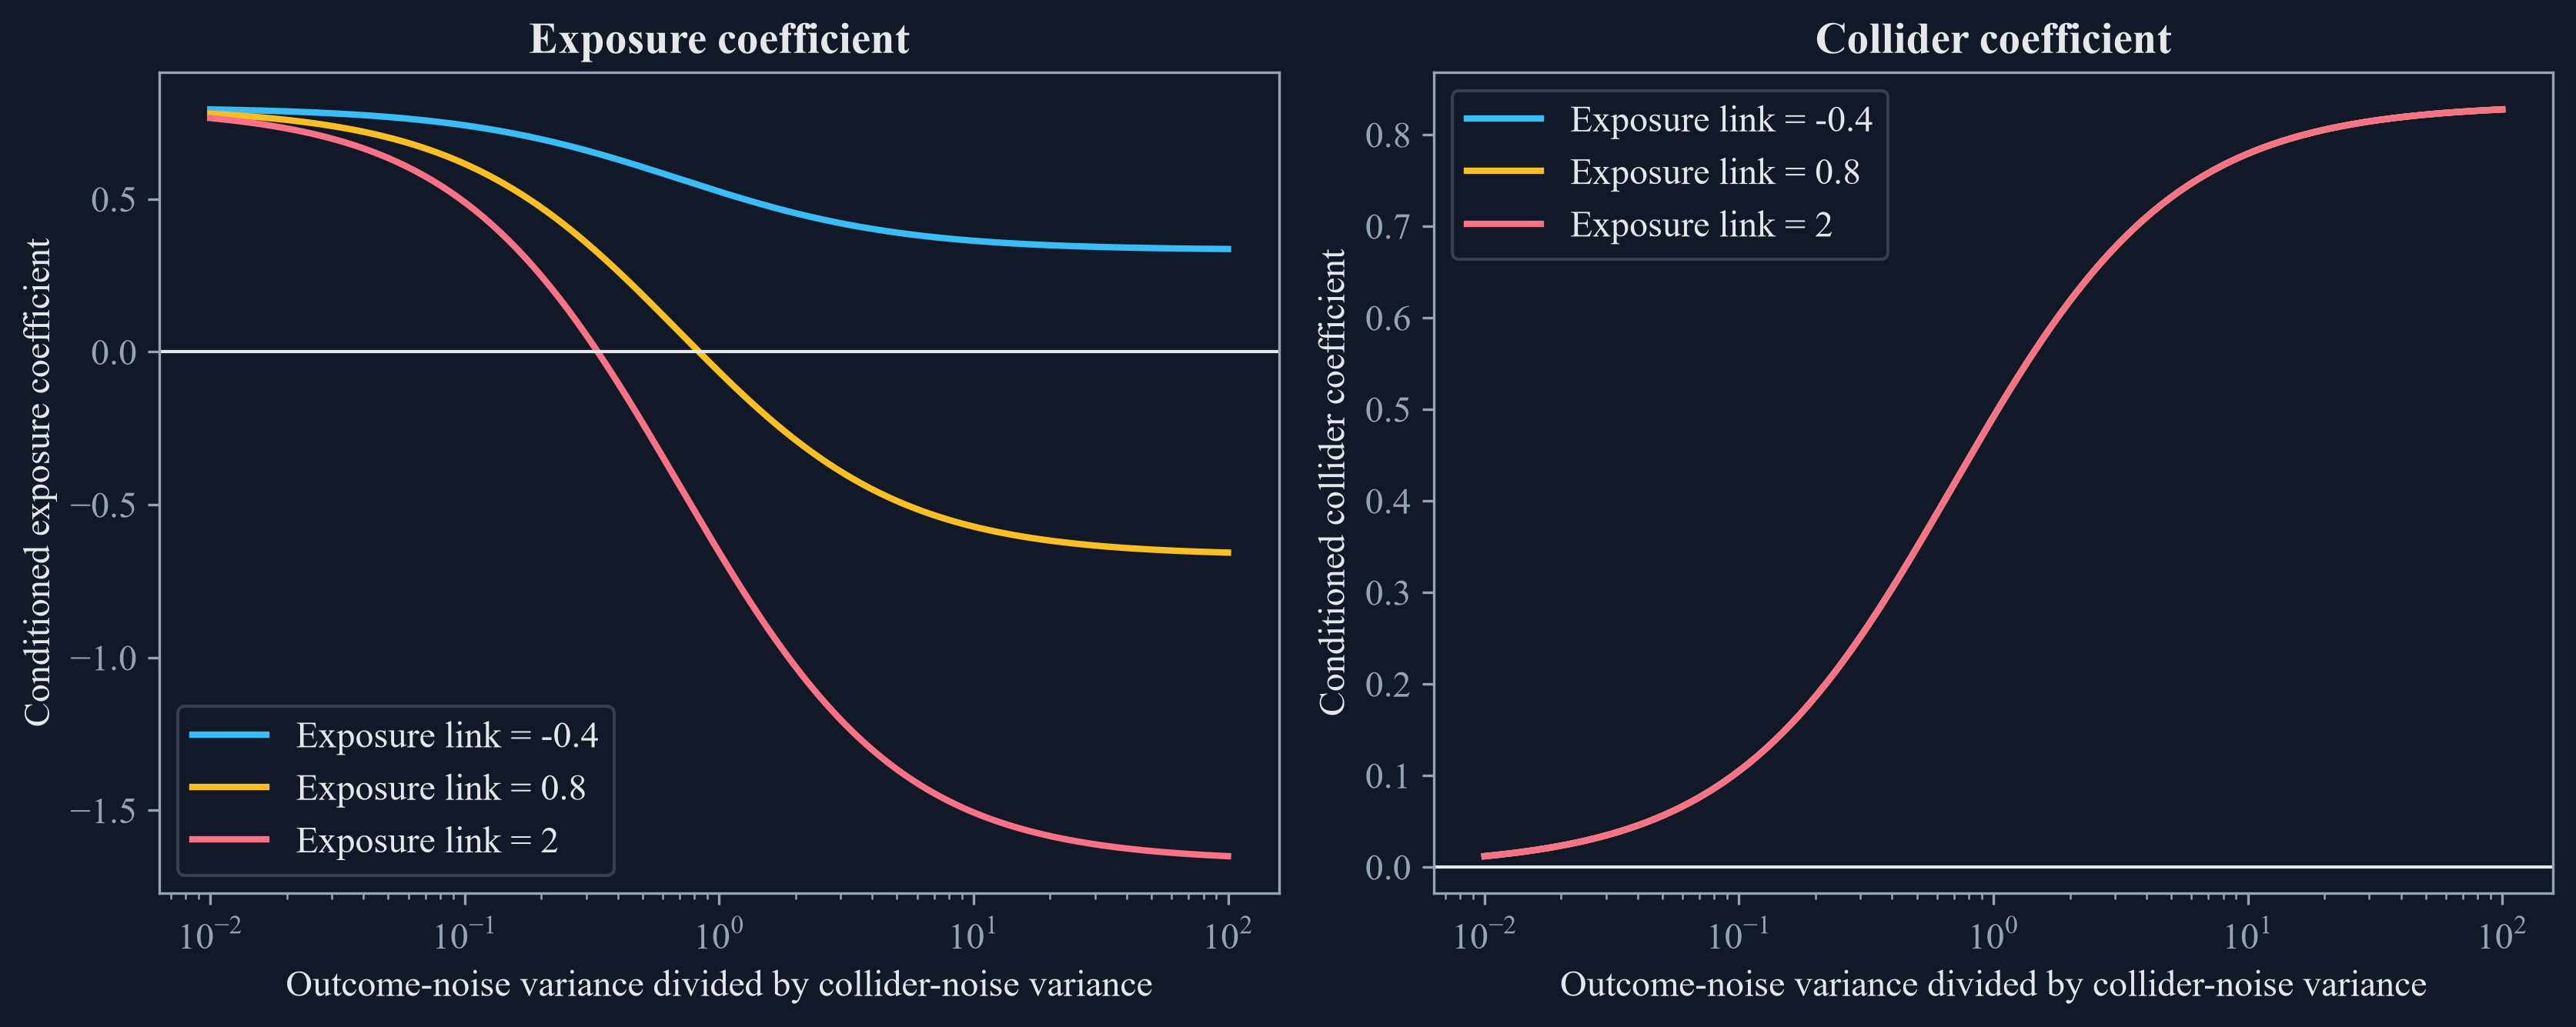

In [2]:
variance_cases = [
    ("Unequal variances", 0.8, 1.2, -0.4, 2.0, 3.0),
    ("Small outcome disturbance", -0.5, 0.75, 2.0, 0.25, 4.0),
    ("Large outcome disturbance", 2.0, -1.0, -0.25, 3.5, 0.5),
    ("No outcome-to-collider link", 1.25, 0.0, 7.0, 5.0, 2.0),
    ("Unit variances", 0.5, 1.0, 0.8, 1.0, 1.0),
]
variance_rows = []
for name, beta, gamma, delta, outcome_variance, collider_variance in variance_cases:
    result = generalized_collider_overcontrolled_coefficients(beta, gamma, delta, outcome_noise_variance=outcome_variance, collider_noise_variance=collider_variance)
    variance_rows.append({"Case": name, "Direct effect": beta, "Outcome link": gamma, "Exposure link": delta, "Outcome-noise variance": outcome_variance, "Collider-noise variance": collider_variance, "Exposure coefficient": result.beta_hat, "Collider coefficient": result.theta_hat})
variance_table = pd.DataFrame(variance_rows)
save_table(variance_table, "collider_general_variance", "Collider-conditioned coefficients with general variances.", "tab:chapter26-collider-general-variance")
display(variance_table)

variance_ratios = np.logspace(-2, 2, 240)
figure, axes = plt.subplots(1, 2, figsize=(11.3, 4.6))
for delta_value, color in [(-0.4, palette["cyan"]), (0.8, palette["amber"]), (2.0, palette["rose"])]:
    results = [generalized_collider_overcontrolled_coefficients(0.8, 1.2, delta_value, outcome_noise_variance=ratio, collider_noise_variance=1.0) for ratio in variance_ratios]
    axes[0].plot(variance_ratios, [value.beta_hat for value in results], color=color, linewidth=2, label=f"Exposure link = {delta_value:g}")
    axes[1].plot(variance_ratios, [value.theta_hat for value in results], color=color, linewidth=2, label=f"Exposure link = {delta_value:g}")
for axis, title, ylabel in [(axes[0], "Exposure coefficient", "Conditioned exposure coefficient"), (axes[1], "Collider coefficient", "Conditioned collider coefficient")]:
    axis.set_xscale("log")
    axis.set_xlabel("Outcome-noise variance divided by collider-noise variance")
    axis.set_ylabel(ylabel)
    axis.set_title(title)
    axis.axhline(0.0, color=palette["text"], linewidth=1.0)
    axis.legend()
figure.tight_layout()
save_figure(figure, "collider_variance_ratio")

## A proxy available before the outcome

The factor and forecast returns from the correct and collider-conditioned rules are:

$$
\begin{aligned}
R_C(x)&=(\beta x)^2,
&R_O(x,\widetilde z)&=\frac{\beta x\{(\beta-\delta\gamma)x+\gamma\widetilde z\}}{1+\gamma^2},\\
F_C&=\beta^2,
&F_O&=\frac{\beta(\beta-\gamma\delta)}{1+\gamma^2}.
\end{aligned}
$$

Here, $R_C$ and $R_O$ are conditional factor returns, $F_C$ and $F_O$ are forecast returns after averaging over the exposure distribution, $x$ is the exposure value, and $\widetilde z$ is a proxy observed before the outcome; it is not the contemporaneous collider $Z$, which already contains $Y$.

,Target,Exposure,Pre-outcome proxy,Direct effect,Outcome link,Exposure link,Correct return,Misspecified return
0,Factor return,1,1,1,1,3,1,-0.5
1,Forecast return,NaN,NaN,1,1,2,1,-0.5


,Boundary,Correct return,Misspecified return
0,Zero direct effect,0,0
1,Direct effect equals link product,4,0
2,Zero outcome-to-collider link,0.36,0.36
3,Zero exposure,0,0


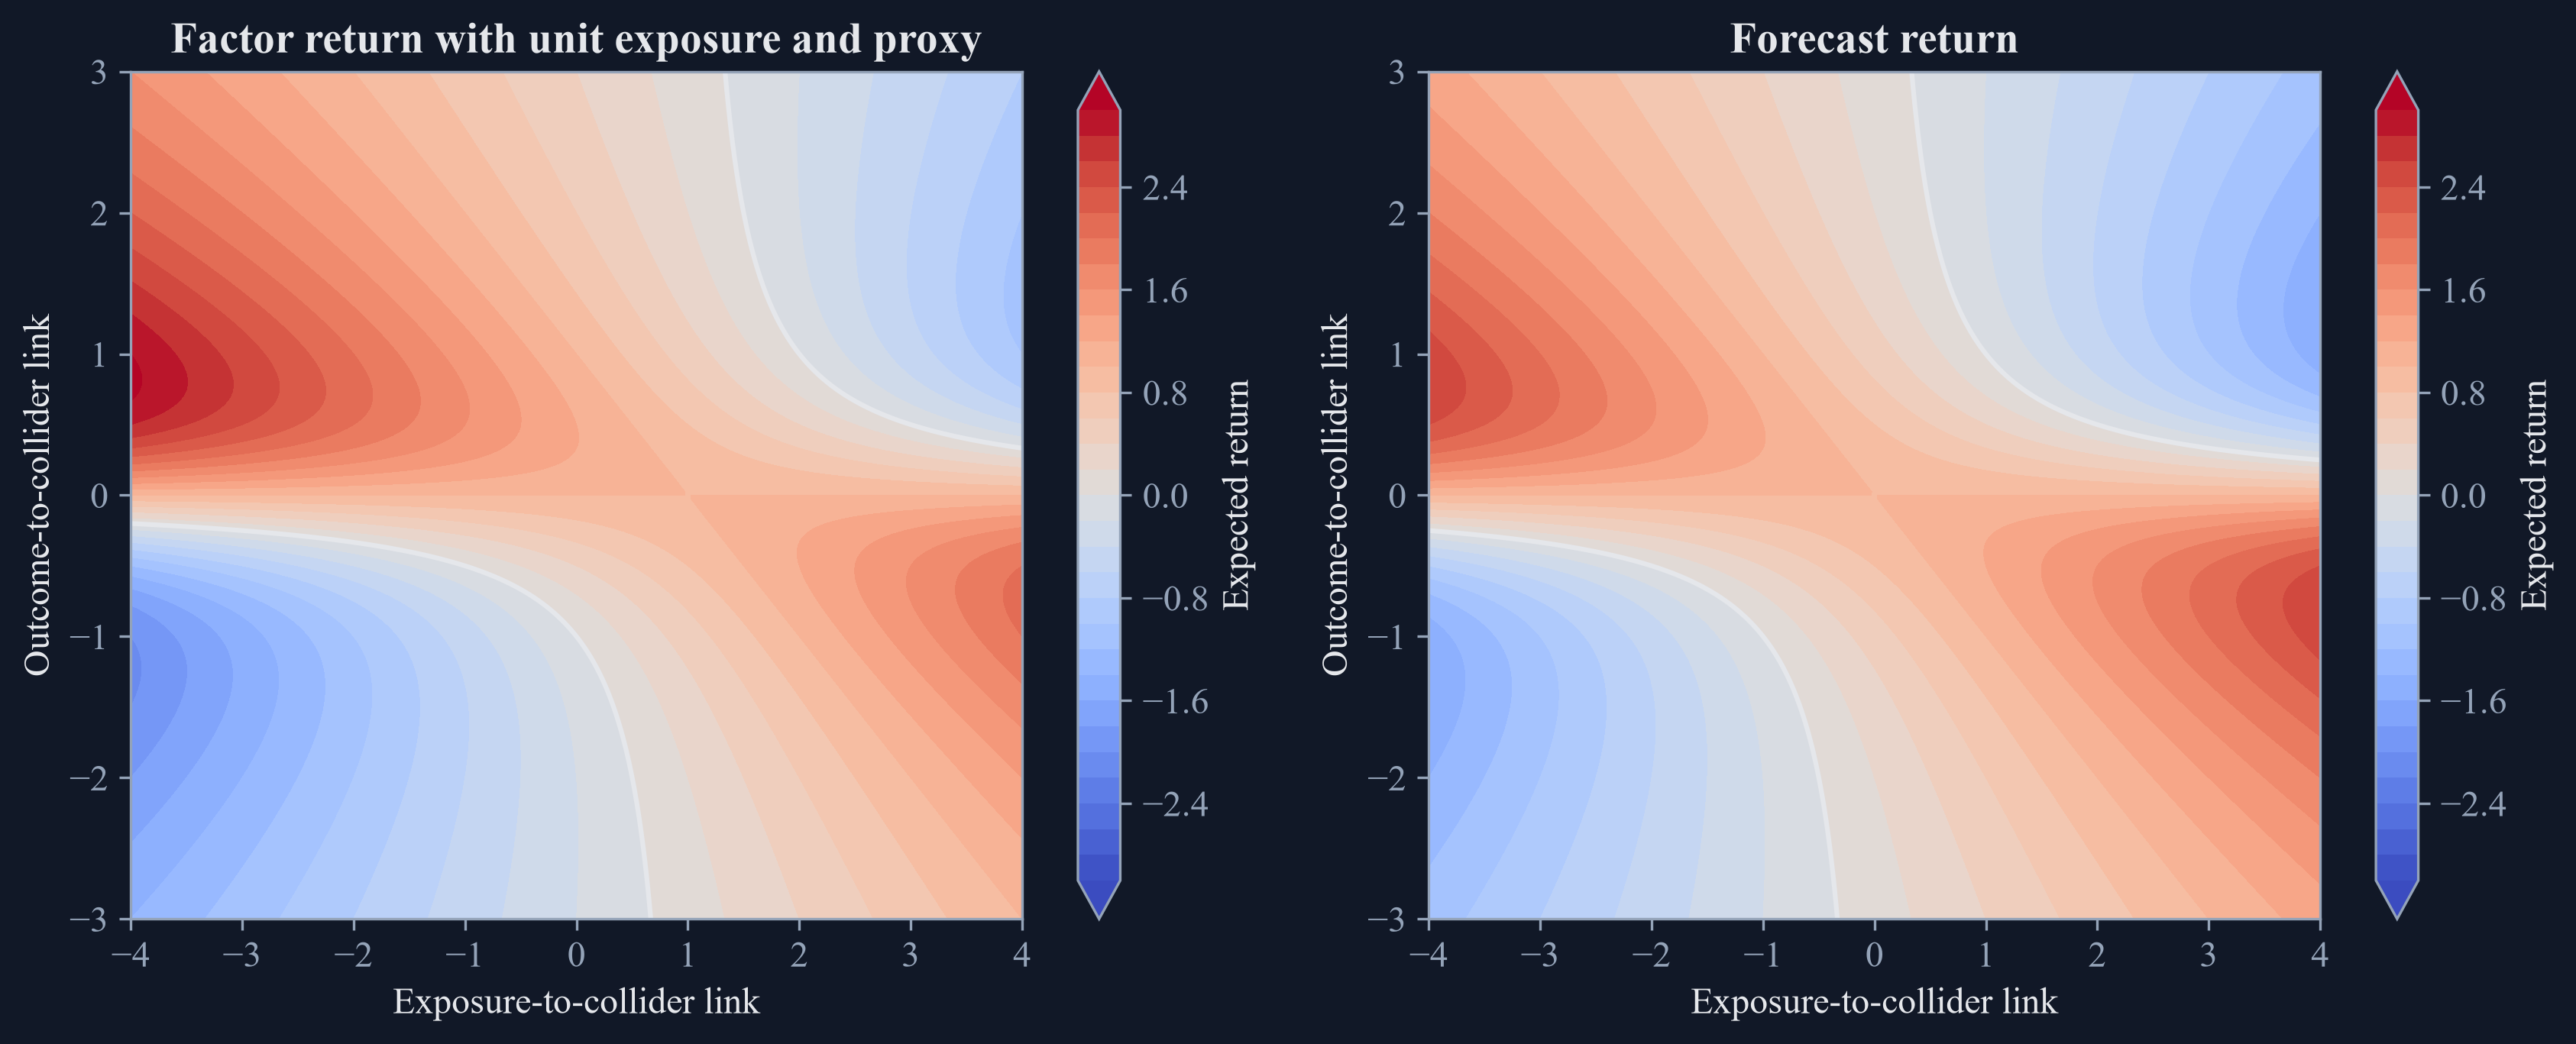

In [3]:
factor_example = collider_factor_return(1.0, 1.0, 1.0, 1.0, 3.0)
forecast_example = collider_forecast_return(1.0, 1.0, 2.0)
return_table = pd.DataFrame([
    {"Target": "Factor return", "Exposure": 1.0, "Pre-outcome proxy": 1.0, "Direct effect": 1.0, "Outcome link": 1.0, "Exposure link": 3.0, "Correct return": factor_example.correct, "Misspecified return": factor_example.misspecified},
    {"Target": "Forecast return", "Exposure": np.nan, "Pre-outcome proxy": np.nan, "Direct effect": 1.0, "Outcome link": 1.0, "Exposure link": 2.0, "Correct return": forecast_example.correct, "Misspecified return": forecast_example.misspecified},
])
save_table(return_table, "collider_return_examples", "Negative expected returns after collider conditioning.", "tab:chapter26-collider-return-examples")
display(return_table)

boundary_table = pd.DataFrame([
    {"Boundary": "Zero direct effect", "Correct return": collider_forecast_return(0.0, 2.0, 3.0).correct, "Misspecified return": collider_forecast_return(0.0, 2.0, 3.0).misspecified},
    {"Boundary": "Direct effect equals link product", "Correct return": collider_forecast_return(2.0, 1.0, 2.0).correct, "Misspecified return": collider_forecast_return(2.0, 1.0, 2.0).misspecified},
    {"Boundary": "Zero outcome-to-collider link", "Correct return": collider_forecast_return(0.6, 0.0, 3.0).correct, "Misspecified return": collider_forecast_return(0.6, 0.0, 3.0).misspecified},
    {"Boundary": "Zero exposure", "Correct return": collider_factor_return(0.0, 4.0, 1.0, 2.0, 3.0).correct, "Misspecified return": collider_factor_return(0.0, 4.0, 1.0, 2.0, 3.0).misspecified},
])
save_table(boundary_table, "collider_return_boundaries", "Exact equality and zero boundaries for collider returns.", "tab:chapter26-collider-return-boundaries")
display(boundary_table)

gamma_values = np.linspace(-3.0, 3.0, 241)
delta_values = np.linspace(-4.0, 4.0, 281)
gamma_mesh, delta_mesh = np.meshgrid(gamma_values, delta_values)
forecast_mesh = (1.0 - gamma_mesh * delta_mesh) / (1.0 + gamma_mesh ** 2)
factor_mesh = ((1.0 - delta_mesh * gamma_mesh) + gamma_mesh) / (1.0 + gamma_mesh ** 2)
figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.7))
for axis, values, title in [(axes[0], factor_mesh, "Factor return with unit exposure and proxy"), (axes[1], forecast_mesh, "Forecast return")]:
    image = axis.contourf(delta_mesh, gamma_mesh, values, levels=np.linspace(-3, 3, 31), cmap="coolwarm", extend="both")
    axis.contour(delta_mesh, gamma_mesh, values, levels=[0.0], colors=[palette["text"]], linewidths=1.5)
    axis.set_xlabel("Exposure-to-collider link")
    axis.set_ylabel("Outcome-to-collider link")
    axis.set_title(title)
    figure.colorbar(image, ax=axis, label="Expected return")
figure.tight_layout()
save_figure(figure, "collider_return_regions")

## Comparing fit after collider adjustment

In the standardized system, explained variance and its adjusted comparison satisfy:

$$
R_C^2=1-\frac{1}{1+\beta^2},
\qquad
R_O^2=1-\frac{1}{(1+\gamma^2)(1+\beta^2)},
\qquad
\overline R_O^2>\overline R_C^2
\Longleftrightarrow
|\gamma|>\frac{1}{\sqrt{n-3}}.
$$

Here, $R_C^2$ and $R_O^2$ are ordinary explained-variance fractions for the correct and overcontrolled regressions, $\overline R_C^2$ and $\overline R_O^2$ are their adjusted versions, $\gamma$ is the outcome-to-collider link, and $n$ is the sample size, which must exceed three.

,Quantity,Value
0,Residual variance after conditioning,0.5
1,Outcome variance,2
2,Correct explained variance,0.5
3,Overcontrolled explained variance,0.75
4,Correct adjusted explained variance,0.333333
5,Overcontrolled adjusted explained variance,0.5
6,Correct exposure-coefficient variance,0.2
7,Overcontrolled exposure-coefficient variance,0.55
8,Collider-coefficient variance,0.05


,Observations,Position,Outcome link,Strict threshold,Correct adjusted explained variance,Overcontrolled adjusted explained variance,Overcontrolled preferred
0,7,Below,0.49,0.5,0.4,0.39521,False
1,7,At,0.5,0.5,0.4,0.4,False
2,7,Above,0.51,0.5,0.4,0.404809,True
3,19,Below,0.245,0.25,0.470588,0.469352,False
4,19,At,0.25,0.25,0.470588,0.470588,False
5,19,Above,0.255,0.25,0.470588,0.471843,True
6,67,Below,0.1225,0.125,0.492308,0.491998,False
7,67,At,0.125,0.125,0.492308,0.492308,False
8,67,Above,0.1275,0.125,0.492308,0.492623,True
9,259,Below,0.06125,0.0625,0.498054,0.497977,False


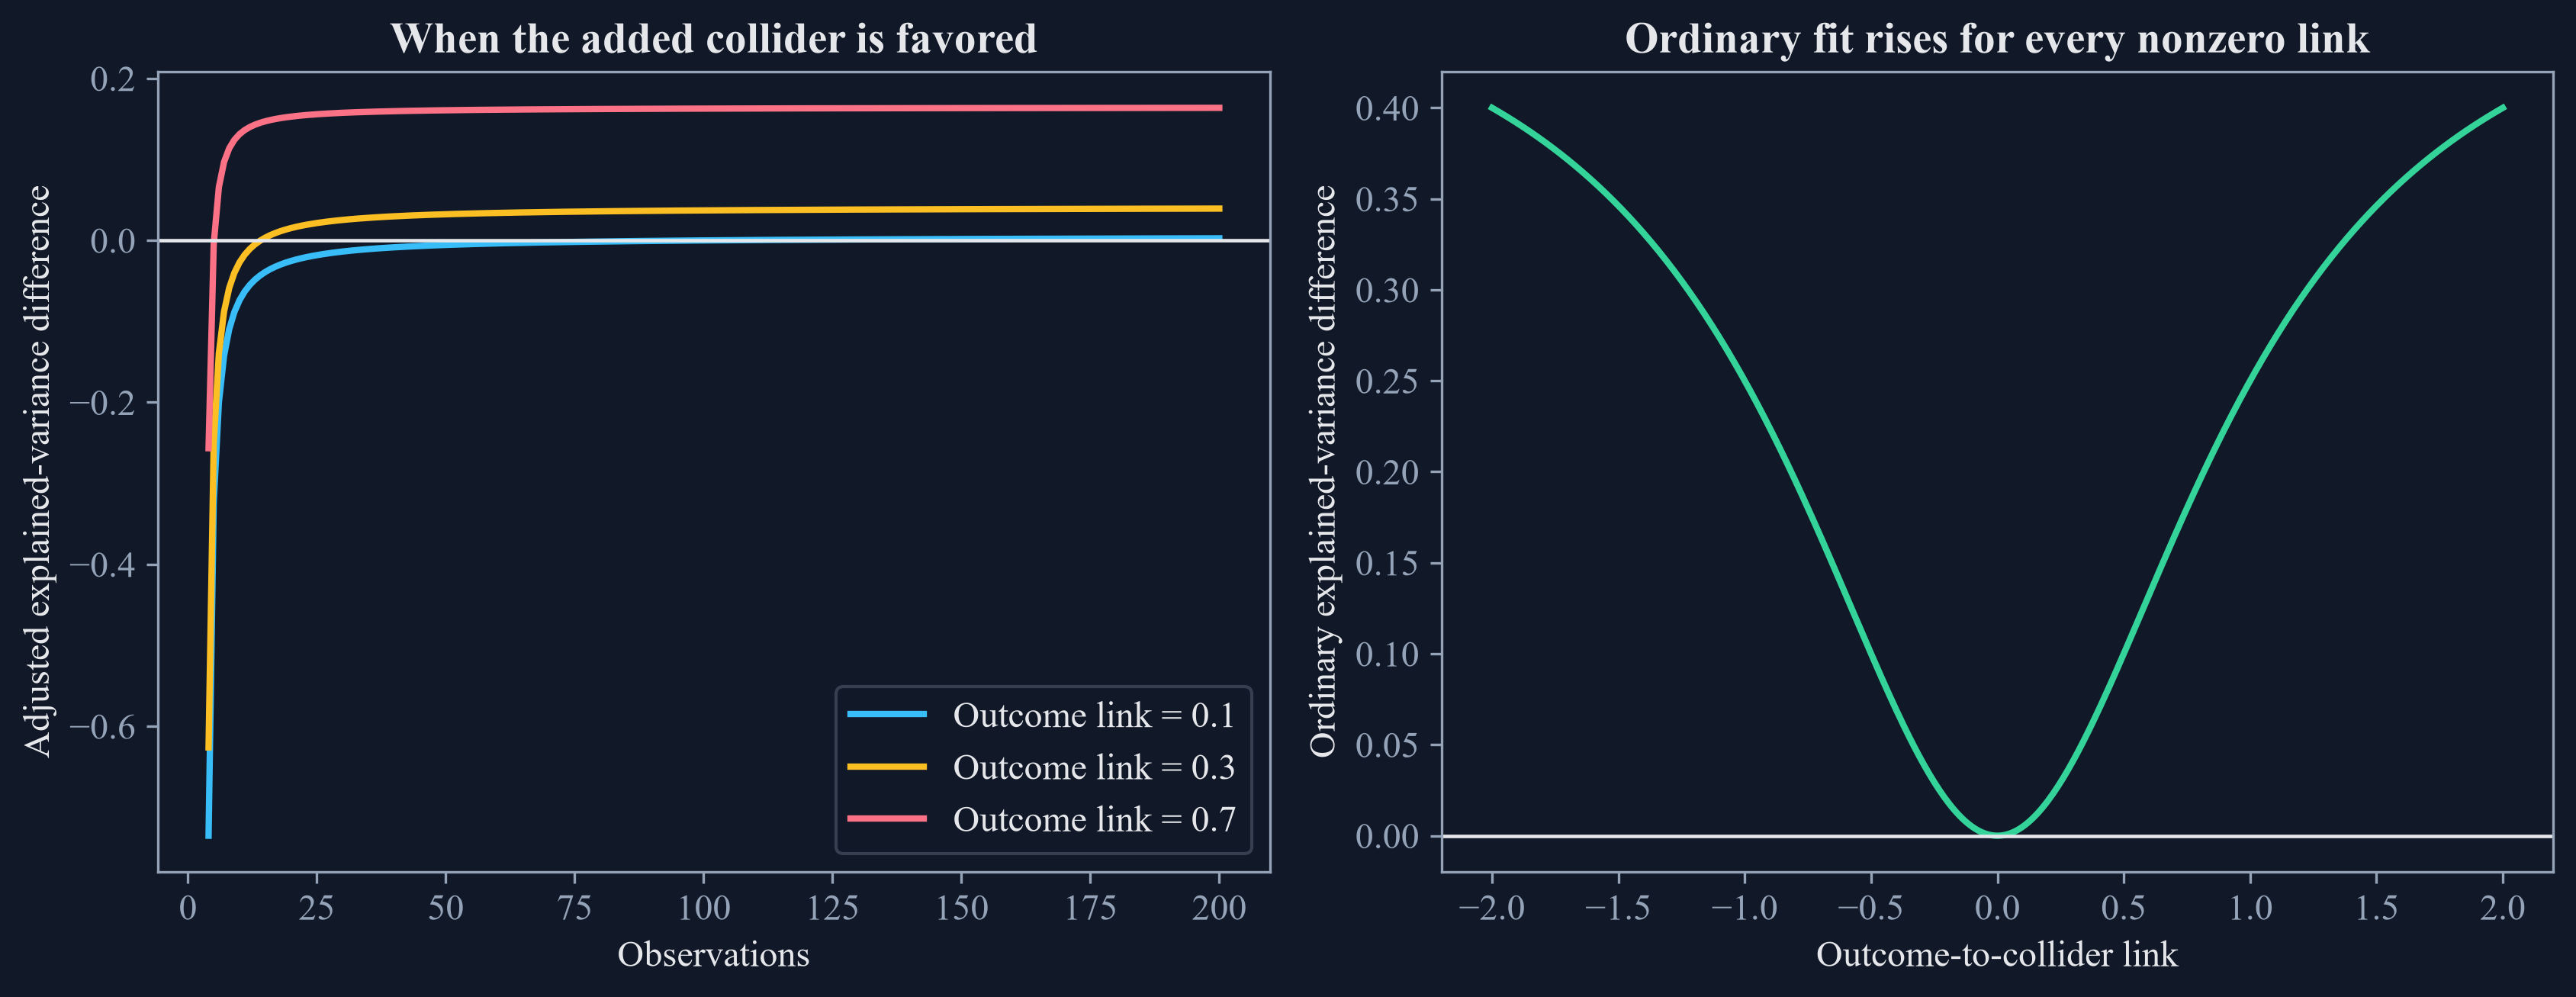

In [4]:
diagnostics = collider_model_diagnostics(1.0, 1.0, 2.0, 5)
diagnostics_table = pd.DataFrame([
    {"Quantity": "Residual variance after conditioning", "Value": diagnostics.residual_variance},
    {"Quantity": "Outcome variance", "Value": diagnostics.outcome_variance},
    {"Quantity": "Correct explained variance", "Value": diagnostics.correct_r_squared},
    {"Quantity": "Overcontrolled explained variance", "Value": diagnostics.overcontrolled_r_squared},
    {"Quantity": "Correct adjusted explained variance", "Value": diagnostics.correct_adjusted_r_squared},
    {"Quantity": "Overcontrolled adjusted explained variance", "Value": diagnostics.overcontrolled_adjusted_r_squared},
    {"Quantity": "Correct exposure-coefficient variance", "Value": diagnostics.correct_beta_variance},
    {"Quantity": "Overcontrolled exposure-coefficient variance", "Value": diagnostics.overcontrolled_beta_variance},
    {"Quantity": "Collider-coefficient variance", "Value": diagnostics.collider_coefficient_variance},
])
save_table(diagnostics_table, "collider_diagnostic_example", "Model-comparison quantities for the released Appendix example.", "tab:chapter26-collider-diagnostic-example")
display(diagnostics_table)

threshold_rows = []
for observations in [7, 19, 67, 259, 1027]:
    threshold = 1.0 / math.sqrt(observations - 3)
    for position, gamma_value in [("Below", threshold * 0.98), ("At", threshold), ("Above", threshold * 1.02)]:
        result = collider_model_diagnostics(1.0, gamma_value, 0.0, observations)
        threshold_rows.append({"Observations": observations, "Position": position, "Outcome link": gamma_value, "Strict threshold": threshold, "Correct adjusted explained variance": result.correct_adjusted_r_squared, "Overcontrolled adjusted explained variance": result.overcontrolled_adjusted_r_squared, "Overcontrolled preferred": result.adjusted_r_squared_prefers_overcontrolled})
threshold_table = pd.DataFrame(threshold_rows)
save_table(threshold_table, "collider_adjusted_threshold", "The strict adjusted explained-variance threshold.", "tab:chapter26-collider-adjusted-threshold")
display(threshold_table)

sample_sizes = np.arange(4, 201)
figure, axes = plt.subplots(1, 2, figsize=(11.4, 4.5))
for gamma_value, color in [(0.1, palette["cyan"]), (0.3, palette["amber"]), (0.7, palette["rose"])]:
    differences = []
    for observations in sample_sizes:
        result = collider_model_diagnostics(1.0, gamma_value, 0.0, int(observations))
        differences.append(result.overcontrolled_adjusted_r_squared - result.correct_adjusted_r_squared)
    axes[0].plot(sample_sizes, differences, color=color, linewidth=2, label=f"Outcome link = {gamma_value:g}")
axes[0].axhline(0.0, color=palette["text"], linewidth=1.1)
axes[0].set_xlabel("Observations")
axes[0].set_ylabel("Adjusted explained-variance difference")
axes[0].set_title("When the added collider is favored")
axes[0].legend()
gamma_line = np.linspace(-2.0, 2.0, 401)
ordinary_gap = [collider_model_diagnostics(1.0, value, 0.0, 50).overcontrolled_r_squared - collider_model_diagnostics(1.0, value, 0.0, 50).correct_r_squared for value in gamma_line]
axes[1].plot(gamma_line, ordinary_gap, color=palette["green"], linewidth=2)
axes[1].axhline(0.0, color=palette["text"], linewidth=1.1)
axes[1].set_xlabel("Outcome-to-collider link")
axes[1].set_ylabel("Ordinary explained-variance difference")
axes[1].set_title("Ordinary fit rises for every nonzero link")
figure.tight_layout()
save_figure(figure, "collider_fit_thresholds")

## Expected coefficient test signals

The population approximation gives the following expected coefficient signals:

$$
t_C=\sqrt n\,\beta,
\qquad
t_O=\frac{\sqrt n(\beta-\delta\gamma)}{\sqrt{(\beta\gamma+\delta)^2+\gamma^2+1}},
\qquad
t_Z=\sqrt n\,\gamma.
$$

Here, $t_C$ is the expected exposure signal in the correct regression, $t_O$ is the expected exposure signal after adding the collider, $t_Z$ is the expected collider-coefficient signal, and $n$, $\beta$, $\gamma$, and $\delta$ retain their earlier meanings; these are expected signals under the stated approximation, not exact p-values.

,Direct effect,Outcome link,Exposure link,Observations,Correct exposure signal,Overcontrolled exposure signal,Collider signal,Larger absolute exposure signal after conditioning
0,0.3,0.8,-0.2,20,1.341641,1.605607,3.577709,True
1,-1,1.5,0.4,100,-10,-7.57622,15,False
2,0,-2,3,8,0,4.535574,-5.656854,True
3,1,1,2,5,2.236068,-0.6742,2.236068,False


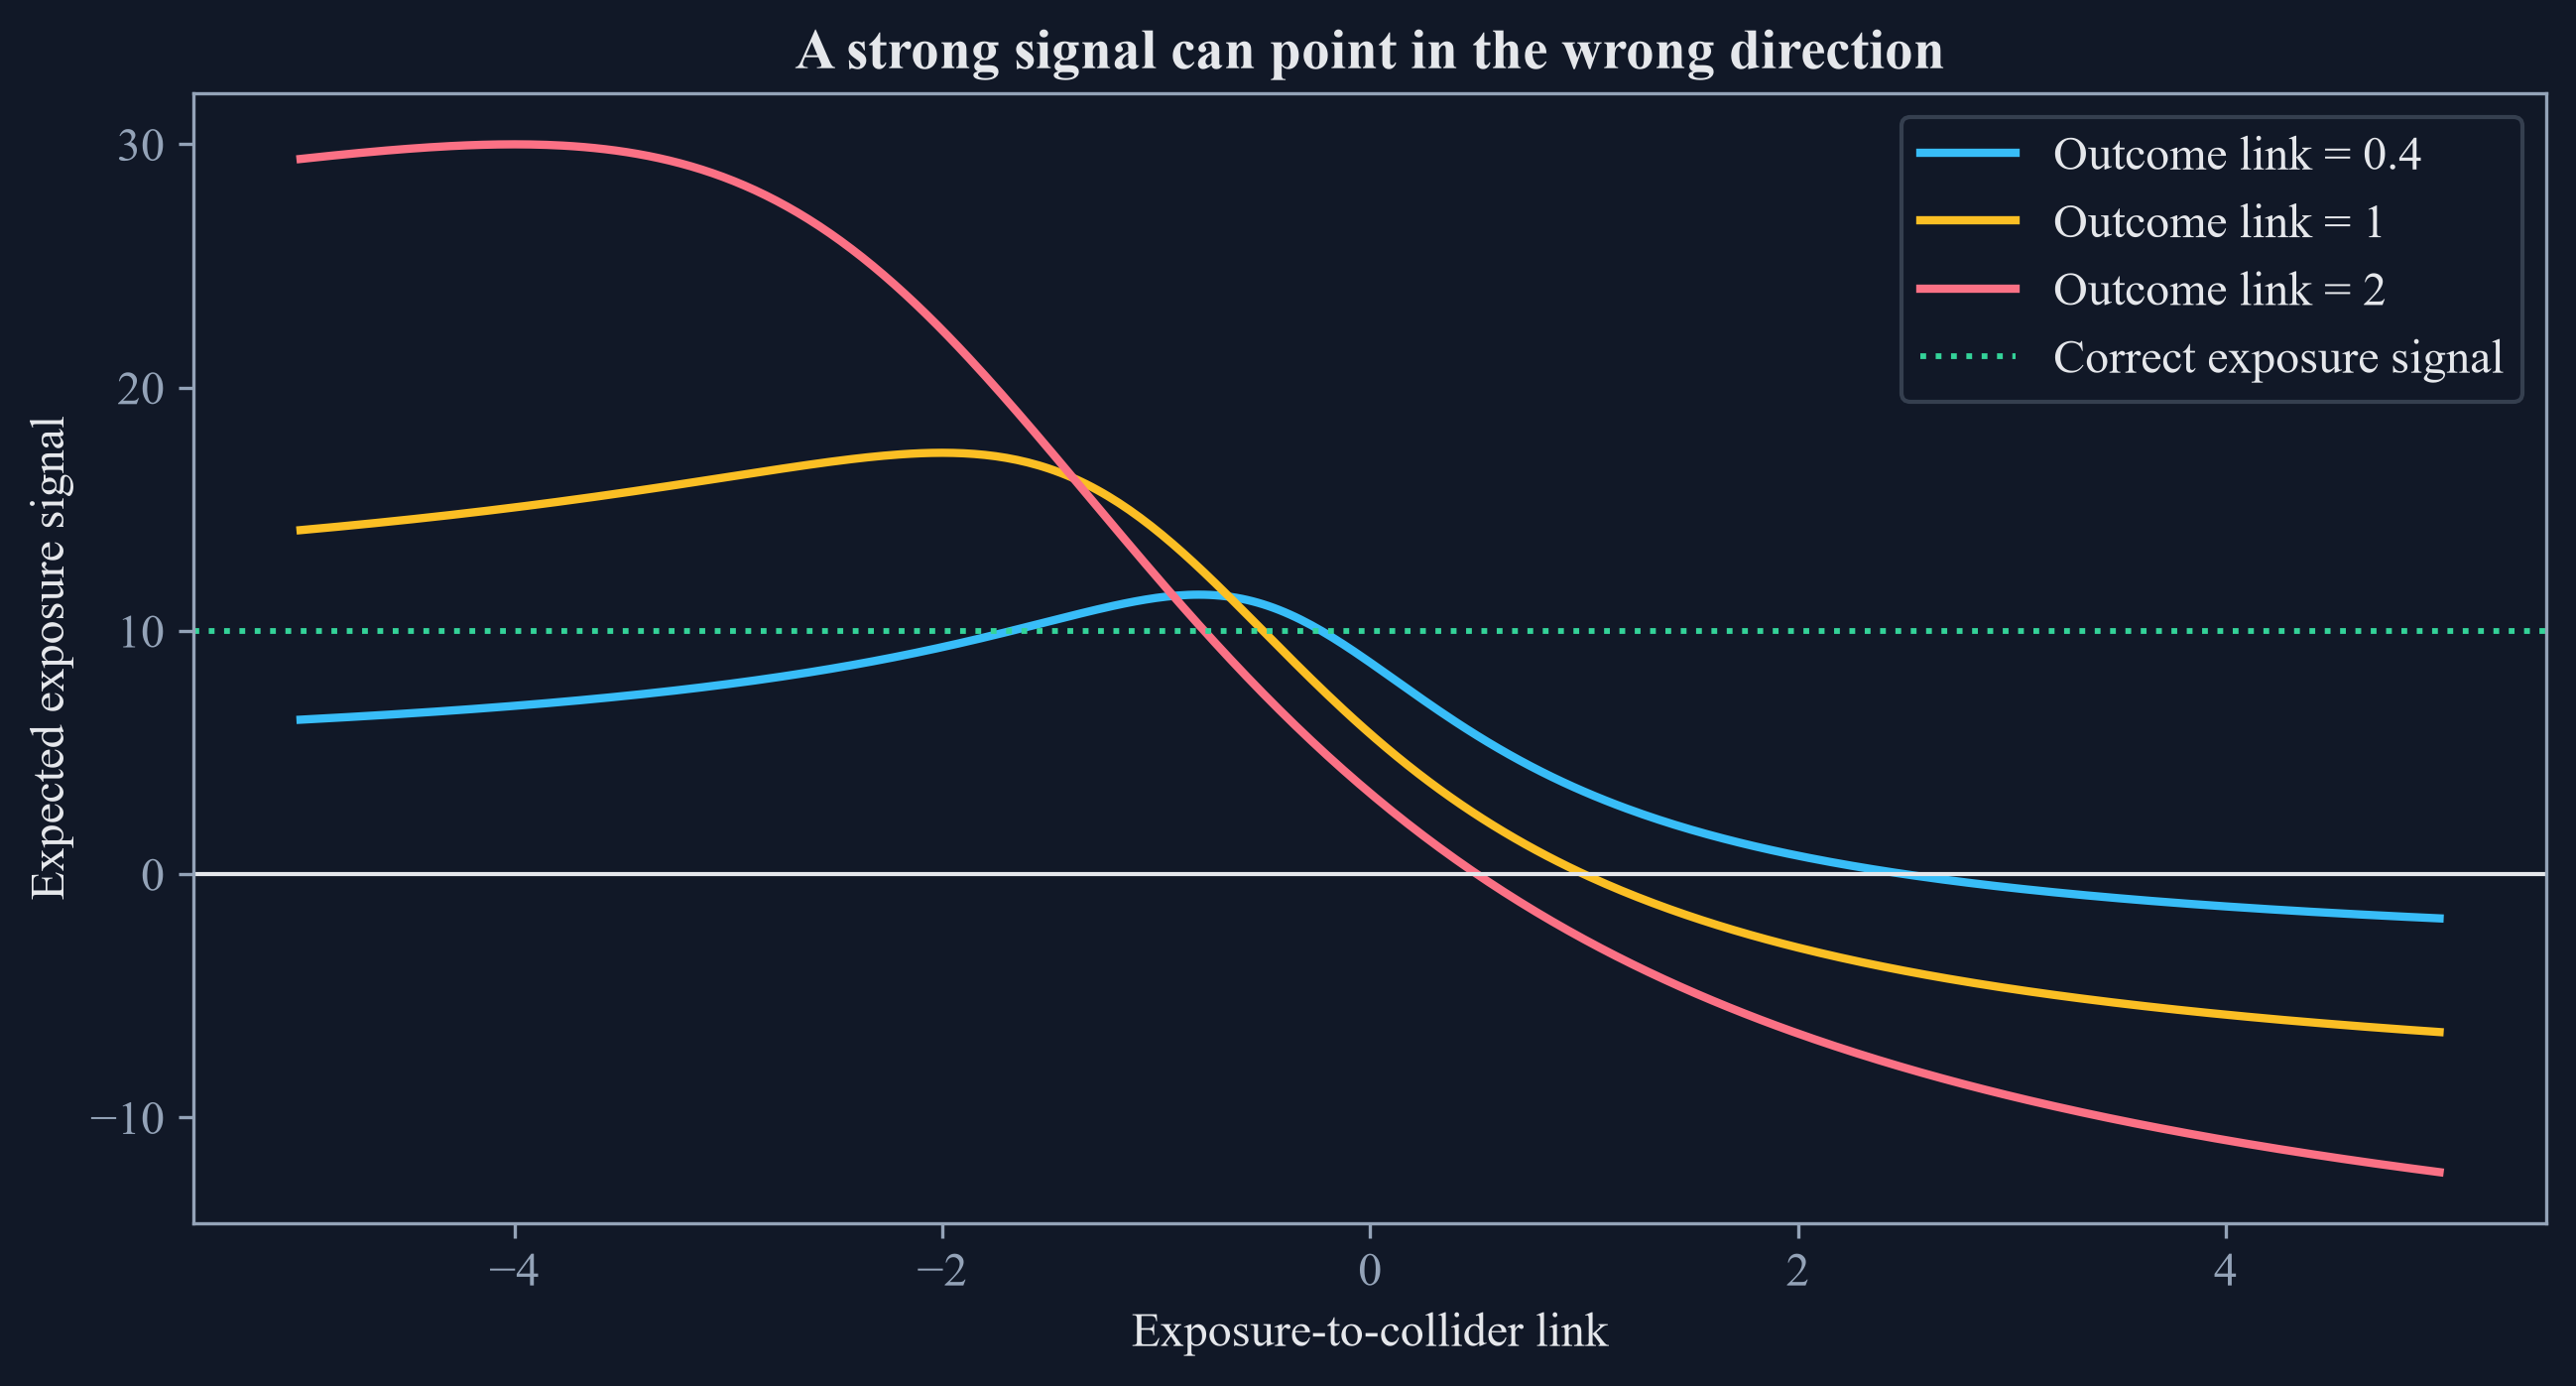

In [5]:
signal_cases = [(0.3, 0.8, -0.2, 20), (-1.0, 1.5, 0.4, 100), (0.0, -2.0, 3.0, 8), (1.0, 1.0, 2.0, 5)]
signal_rows = []
for beta, gamma, delta, observations in signal_cases:
    result = collider_model_diagnostics(beta, gamma, delta, observations)
    signal_rows.append({"Direct effect": beta, "Outcome link": gamma, "Exposure link": delta, "Observations": observations, "Correct exposure signal": result.correct_beta_t_statistic, "Overcontrolled exposure signal": result.overcontrolled_beta_t_statistic, "Collider signal": result.collider_t_statistic, "Larger absolute exposure signal after conditioning": result.absolute_beta_t_prefers_overcontrolled})
signal_table = pd.DataFrame(signal_rows)
save_table(signal_table, "collider_expected_signals", "Expected coefficient signals under the population approximation.", "tab:chapter26-collider-expected-signals")
display(signal_table)

delta_line = np.linspace(-5.0, 5.0, 401)
figure, axis = plt.subplots(figsize=(8.8, 4.8))
for gamma_value, color in [(0.4, palette["cyan"]), (1.0, palette["amber"]), (2.0, palette["rose"])]:
    signals = [collider_model_diagnostics(1.0, gamma_value, delta_value, 100).overcontrolled_beta_t_statistic for delta_value in delta_line]
    axis.plot(delta_line, signals, color=color, linewidth=2, label=f"Outcome link = {gamma_value:g}")
axis.axhline(10.0, color=palette["green"], linewidth=1.4, linestyle=":", label="Correct exposure signal")
axis.axhline(0.0, color=palette["text"], linewidth=1.0)
axis.set_xlabel("Exposure-to-collider link")
axis.set_ylabel("Expected exposure signal")
axis.set_title("A strong signal can point in the wrong direction")
axis.legend()
figure.tight_layout()
save_figure(figure, "collider_expected_signal_paths")

## Checking selection inputs at their boundaries

In the simple collider system $Z=X+Y+V$ with independent unit-variance inputs, conditioning creates the covariance:

$$
\operatorname{Cov}(X,Y\mid Z)
=\operatorname{Cov}(X,Y)
-\frac{\operatorname{Cov}(X,Z)\operatorname{Cov}(Z,Y)}{\operatorname{Var}(Z)}
=-\frac{1}{3}.
$$

Here, $X$ and $Y$ are marginally independent causes of the collider $Z$, $V$ is the collider disturbance, and the negative conditional covariance is created by holding their common outcome fixed.

,Specification,Exposure coefficient,Population target,Collider coefficient,Explained variance
0,Collider omitted,0.001504,0,NaN,0.000002
1,Collider included,-0.496296,-0.5,0.498828,0.499189
2,Conditional covariance identity,-0.333333,-0.333333,NaN,NaN


,Check,Expected result,Observed result,Passed
0,Boolean observation count,ValueError,ValueError,True
1,Noninteger observation count,ValueError,ValueError,True
2,Too few observations,ValueError,ValueError,True
3,Boolean coefficient,ValueError,ValueError,True
4,Nonfinite coefficient,ValueError,ValueError,True
5,Zero outcome-noise variance,ValueError,ValueError,True
6,Negative collider-noise variance,ValueError,ValueError,True
7,Required variance arguments omitted,TypeError,TypeError,True


,Check,Value,Expected value,Passed
0,Large-link exposure coefficient,0,0,True
1,Large-link collider coefficient,0,0,True
2,Representable coefficient variance,0,0,True
3,Negative sign survives near cancellation,0,0,True


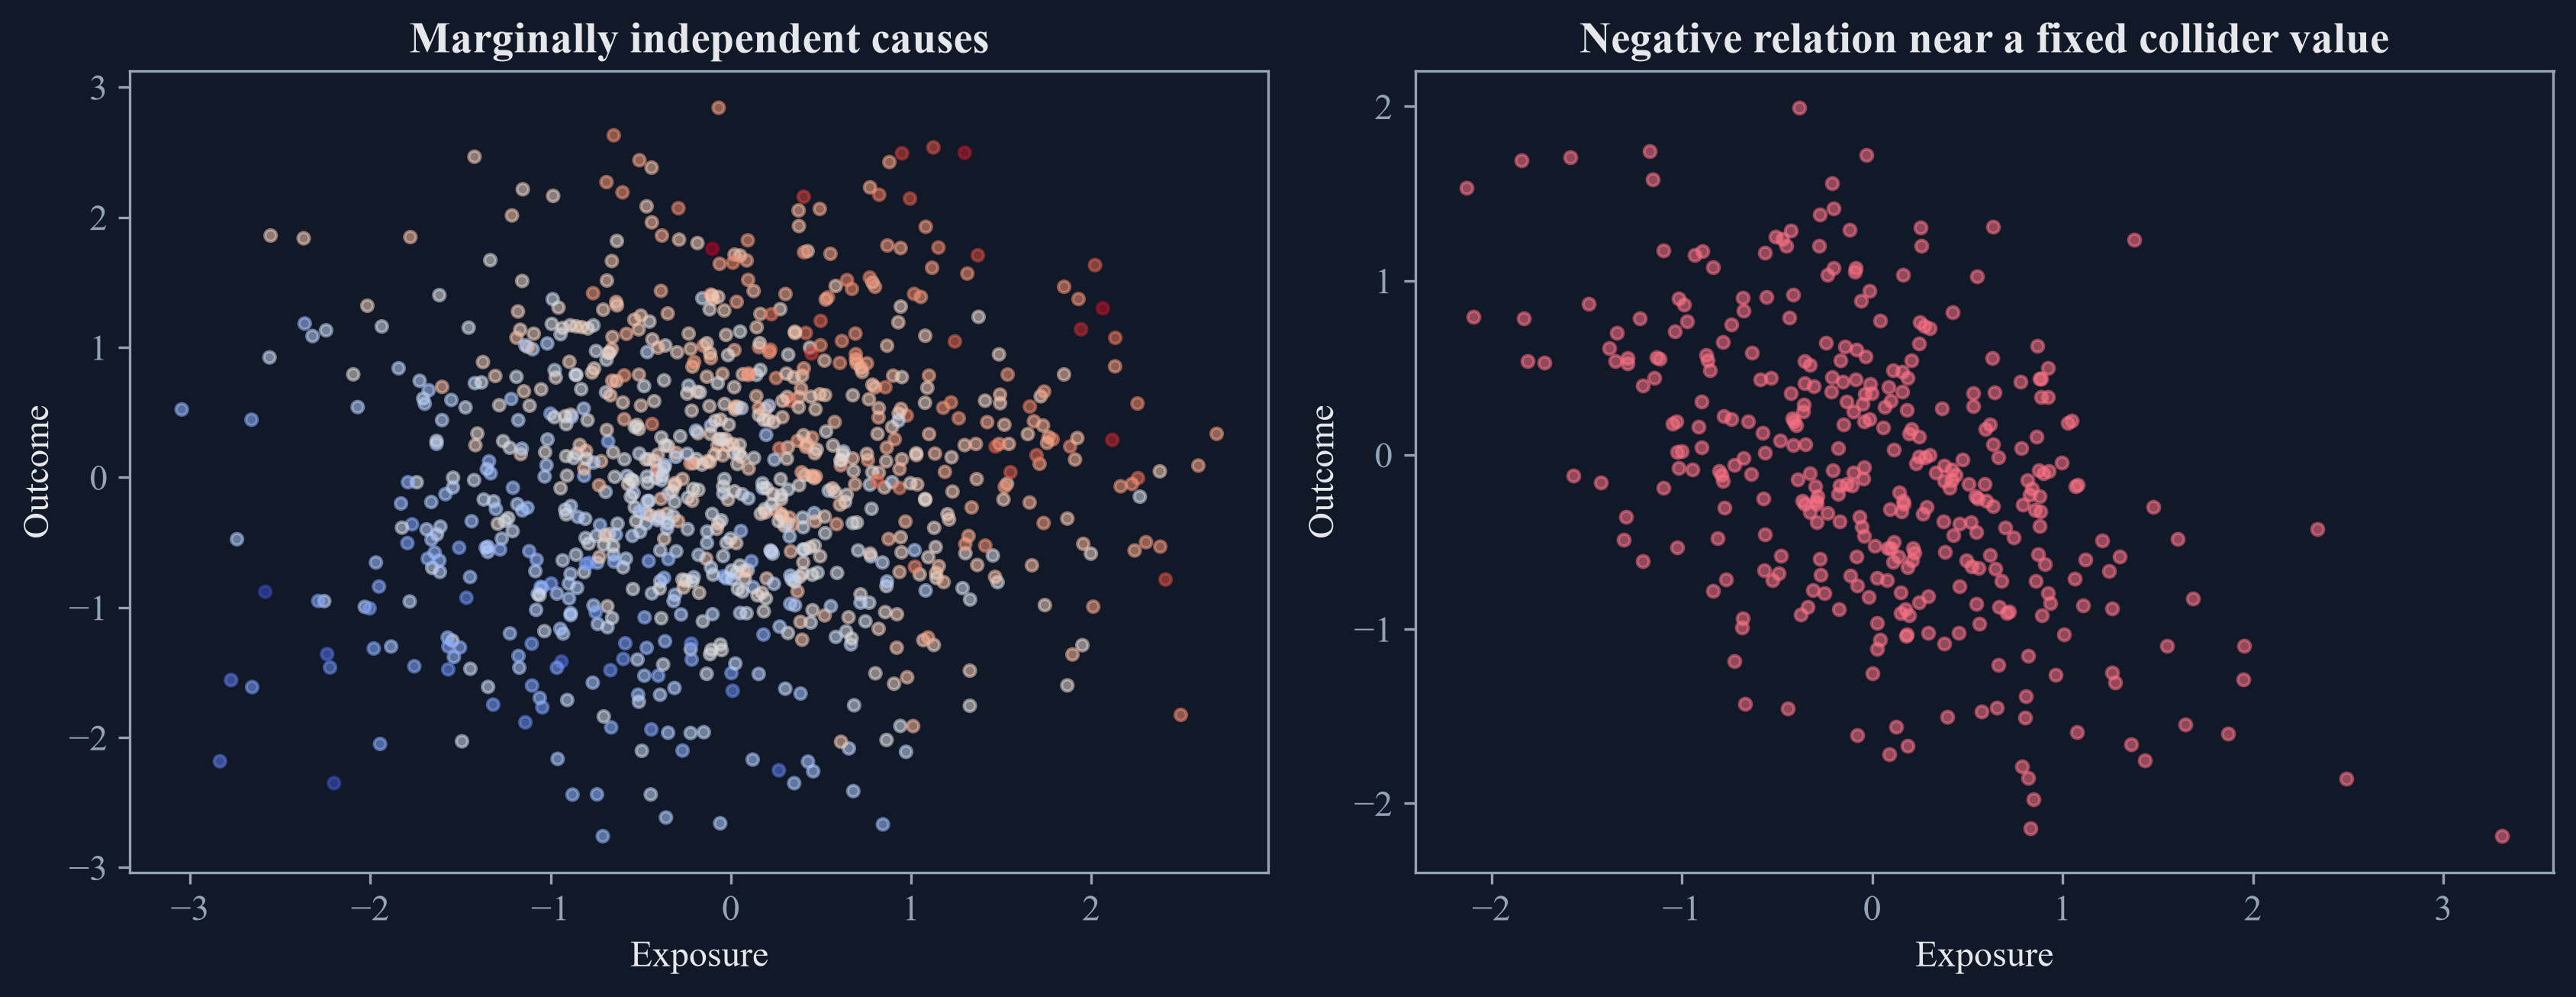

,Question,Answer
0,Is the collider a cause of the outcome?,No
1,Can conditioning change the exposure coefficie...,Yes
2,Can ordinary explained variance improve?,"Yes, for every nonzero outcome link"
3,Are the returned test quantities exact p-values?,No
4,Does the factor calculation use the contempora...,"No, it uses a pre-outcome proxy"


In [6]:
random_state = np.random.RandomState(0)
simple_exposure = random_state.standard_normal(5000)
simple_outcome = random_state.standard_normal(5000)
simple_noise = random_state.standard_normal(5000)
simple_collider = simple_exposure + simple_outcome + simple_noise
marginal_diagnostics, marginal_r2, _, _ = ols_diagnostics(simple_outcome, {"Exposure": simple_exposure})
selected_diagnostics, selected_r2, _, _ = ols_diagnostics(simple_outcome, {"Exposure": simple_exposure, "Collider": simple_collider})
conditional_table = pd.DataFrame([
    {"Specification": "Collider omitted", "Exposure coefficient": marginal_diagnostics.loc[1, "Estimate"], "Population target": 0.0, "Collider coefficient": np.nan, "Explained variance": marginal_r2},
    {"Specification": "Collider included", "Exposure coefficient": selected_diagnostics.loc[1, "Estimate"], "Population target": -0.5, "Collider coefficient": selected_diagnostics.loc[2, "Estimate"], "Explained variance": selected_r2},
    {"Specification": "Conditional covariance identity", "Exposure coefficient": -1.0 / 3.0, "Population target": -1.0 / 3.0, "Collider coefficient": np.nan, "Explained variance": np.nan},
])
save_table(conditional_table, "collider_conditional_selection", "Marginal independence and collider-induced conditional association.", "tab:chapter26-collider-conditional-selection")
display(conditional_table)

input_checks = pd.DataFrame([
    contract_result("Boolean observation count", lambda: collider_model_diagnostics(1.0, 1.0, 1.0, True), "ValueError"),
    contract_result("Noninteger observation count", lambda: collider_model_diagnostics(1.0, 1.0, 1.0, 4.0), "ValueError"),
    contract_result("Too few observations", lambda: collider_model_diagnostics(1.0, 1.0, 1.0, 3), "ValueError"),
    contract_result("Boolean coefficient", lambda: collider_overcontrolled_coefficients(True, 1.0, 1.0), "ValueError"),
    contract_result("Nonfinite coefficient", lambda: collider_forecast_return(np.nan, 1.0, 1.0), "ValueError"),
    contract_result("Zero outcome-noise variance", lambda: generalized_collider_overcontrolled_coefficients(1.0, 1.0, 1.0, outcome_noise_variance=0.0, collider_noise_variance=1.0), "ValueError"),
    contract_result("Negative collider-noise variance", lambda: generalized_collider_overcontrolled_coefficients(1.0, 1.0, 1.0, outcome_noise_variance=1.0, collider_noise_variance=-1.0), "ValueError"),
    contract_result("Required variance arguments omitted", lambda: generalized_collider_overcontrolled_coefficients(1.0, 1.0, 1.0), "TypeError"),
])
save_table(input_checks, "collider_input_checks", "Input-boundary checks for collider calculations.", "tab:chapter26-collider-input-checks")
display(input_checks)

extreme_coefficients = collider_overcontrolled_coefficients(1.0, 1e308, 1.0)
extreme_diagnostics = collider_model_diagnostics(1e154, 1e200, 0.0, 4)
sign_value = collider_forecast_return(1.0, -1e-10, -1e10).misspecified
numerical_table = pd.DataFrame([
    {"Check": "Large-link exposure coefficient", "Value": extreme_coefficients.beta_hat, "Expected value": -1e-308, "Passed": np.isclose(extreme_coefficients.beta_hat, -1e-308, rtol=1e-15, atol=0.0)},
    {"Check": "Large-link collider coefficient", "Value": extreme_coefficients.theta_hat, "Expected value": 1e-308, "Passed": np.isclose(extreme_coefficients.theta_hat, 1e-308, rtol=1e-15, atol=0.0)},
    {"Check": "Representable coefficient variance", "Value": extreme_diagnostics.overcontrolled_beta_variance, "Expected value": 2.5e-93, "Passed": np.isclose(extreme_diagnostics.overcontrolled_beta_variance, 2.5e-93, rtol=1e-14)},
    {"Check": "Negative sign survives near cancellation", "Value": sign_value, "Expected value": -3.643219731549774e-17, "Passed": sign_value < 0.0},
])
save_table(numerical_table, "collider_numerical_stability", "Finite-scaling and sign-preservation checks for collider calculations.", "tab:chapter26-collider-numerical-stability", float_format="%.12g")
display(numerical_table)

figure, axes = plt.subplots(1, 2, figsize=(11.4, 4.5))
draw_index = np.arange(900)
axes[0].scatter(simple_exposure[draw_index], simple_outcome[draw_index], c=simple_collider[draw_index], cmap="coolwarm", s=13, alpha=0.55)
axes[0].set_xlabel("Exposure")
axes[0].set_ylabel("Outcome")
axes[0].set_title("Marginally independent causes")
selected_band = np.abs(simple_collider) < 0.15
axes[1].scatter(simple_exposure[selected_band], simple_outcome[selected_band], color=palette["rose"], s=14, alpha=0.55)
axes[1].set_xlabel("Exposure")
axes[1].set_ylabel("Outcome")
axes[1].set_title("Negative relation near a fixed collider value")
figure.tight_layout()
save_figure(figure, "collider_selection_view")

section_summary = pd.DataFrame([
    {"Question": "Is the collider a cause of the outcome?", "Answer": "No"},
    {"Question": "Can conditioning change the exposure coefficient sign?", "Answer": "Yes"},
    {"Question": "Can ordinary explained variance improve?", "Answer": "Yes, for every nonzero outcome link"},
    {"Question": "Are the returned test quantities exact p-values?", "Answer": "No"},
    {"Question": "Does the factor calculation use the contemporaneous collider?", "Answer": "No, it uses a pre-outcome proxy"},
])
save_table(section_summary, "collider_section_summary", "Main conclusions from the collider experiments.", "tab:chapter26-collider-section-summary")
display(section_summary)

## Tests

In [7]:
assert collider_overcontrolled_coefficients(0.7, 0.0, 4.0) == ColliderCoefficients(beta_hat=0.7, theta_hat=0.0)
assert factor_example == StrategyPerformance(correct=1.0, misspecified=-0.5)
assert forecast_example == StrategyPerformance(correct=1.0, misspecified=-0.5)
assert diagnostics == ColliderDiagnostics(residual_variance=0.5, outcome_variance=2.0, correct_r_squared=0.5, overcontrolled_r_squared=0.75, correct_adjusted_r_squared=1.0 / 3.0, overcontrolled_adjusted_r_squared=0.5, correct_beta_variance=0.2, overcontrolled_beta_variance=11.0 / 20.0, collider_coefficient_variance=0.05, correct_beta_t_statistic=math.sqrt(5.0), overcontrolled_beta_t_statistic=-math.sqrt(5.0 / 11.0), collider_t_statistic=math.sqrt(5.0), adjusted_r_squared_prefers_overcontrolled=True, absolute_beta_t_prefers_overcontrolled=False)
assert not threshold_table.loc[threshold_table["Position"] == "At", "Overcontrolled preferred"].any()
assert input_checks["Passed"].all()
assert numerical_table["Passed"].all()
for stem in ["collider_graph_and_coefficient", "collider_variance_ratio", "collider_return_regions", "collider_fit_thresholds", "collider_expected_signal_paths", "collider_selection_view"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["collider_standardized_coefficients", "collider_generated_check", "collider_general_variance", "collider_return_examples", "collider_return_boundaries", "collider_diagnostic_example", "collider_adjusted_threshold", "collider_expected_signals", "collider_conditional_selection", "collider_input_checks", "collider_numerical_stability", "collider_section_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()